In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from collections import Counter
import math

In [2]:
excel_url = "C:/Users/Next/Downloads/AnonymizedPatientsTable.csv"

In [3]:
df = pd.read_csv(excel_url)

last_col = df.columns[-1]
if str(last_col).startswith("Unnamed"):
    df = df.rename(columns={last_col: "Code"})
else:
    df = df.rename(columns={last_col: "Code"})

df = df.drop(columns=["Birthday"])

# delete patients without PET or CT
df = df[df["PET"].str.lower().str.strip() == "yes"]
df = df[df["CT"].str.lower().str.strip() == "yes"]

#delete empty columns
df = df.dropna(axis=1, how="all")
print(df.columns.tolist())

['Gender', 'Age', 'Biopsy positive', 'CT', 'PET', 'TYPE', 'Subtype+ Notes', 'Code']


In [4]:
print(df.head())

  Gender  Age               Biopsy positive   CT  PET  \
1      M   75  CK AE1/AE3,CEA,CK7,TTF1,KI67  yes  yes   
2      M   68                TTF1,NAPSIN AM  yes  yes   
3      M   63                    P63,CK HMW  yes  yes   
4      M   71               TTF1,CK-AE1/AE3  yes  yes   
5      F   78                           P63  yes  yes   

                      TYPE Subtype+ Notes    Code  
1           Adenocarcinoma            NaN  3111.0  
2           Adenocarcinoma            NaN  4111.0  
3                NSCLC-NOS            NaN  5111.0  
4           Adenocarcinoma            NaN  6111.0  
5  Squamous cell carcinoma            NaN  7011.0  


In [5]:
# number of each type of cancer
counts = df["TYPE"].value_counts()
print(counts)

TYPE
Adenocarcinoma             72
Squamous cell carcinoma    21
NSCLC-NOS                   3
MIXED                       1
Epitheloid                  1
Name: count, dtype: int64


In [6]:
markers = df["Biopsy positive"].dropna()
all_markers = []
for m in markers:
    parts = [x.strip().upper() for x in m.split(",") if x.strip()]
    all_markers.extend(parts)

marker_counts = Counter(all_markers)

marker_df = pd.DataFrame(marker_counts.items(), columns=["Marker", "Nr_of_appearances"])
marker_df = marker_df.sort_values(by="Nr_of_appearances", ascending=False).reset_index(drop=True)

# number of appearances of each marker
print(marker_df)

                Marker  Nr_of_appearances
0                 TTF1                 63
1                  CK7                 42
2               NAPSIN                 22
3                  P40                 16
4             NAPSIN A                 15
5                  P63                 11
6                  CK5                 11
7            NOT GIVEN                  8
8           CK-AE1/AE3                  6
9                 KI67                  5
10          CK AE1/AE3                  4
11                CDX2                  4
12              CK HMW                  2
13                CD56                  2
14                 CEA                  1
15            NECROSIS                  1
16          SS-CATENIN                  1
17            CKA1/AE3                  1
18           NAPSIN AM                  1
19  GRANULAR CYTOPLASM                  1
20                CK20                  1
21                   ?                  1
22                 WT1            

In [7]:
# convert age to numeric value
df["Age"] = pd.to_numeric(df.get("Age", pd.Series(dtype=float)), errors="coerce")

# clean whitespace
def norm_str(x):
    if pd.isna(x):
        return x
    return str(x).strip()

for col in ["Gender", "PET", "CT", "TYPE", "Subtype+ Notes", "Biopsy positive"]:
    if col in df.columns:
        df[col] = df[col].map(norm_str)

In [18]:
def get_patients_codes():
    if "Code" in df.columns:
        df["Code"] = df["Code"].dropna()
    codes = (
        df["Code"]
        .dropna()
        .apply(lambda x: int(float(x)))
        .tolist()
    )
    return codes


In [20]:
patients_codes = get_patients_codes()
print("Patient codes:", patients_codes)

Patient codes: [3111, 4111, 5111, 6111, 7011, 8011, 9111, 10111, 11111, 12111, 13111, 14011, 15011, 16111, 17011, 19111, 20011, 21011, 22011, 23111, 24111, 25111, 26011, 28111, 29111, 30011, 31011, 32111, 33111, 34011, 35111, 36111, 37011, 38111, 40011, 41111, 42111, 43011, 44111, 45111, 46011, 47111, 48011, 49111, 50011, 51011, 52011, 53111, 54011, 55011, 56111, 57111, 58011, 59111, 60011, 61011, 62011, 63111, 64011, 65111, 66011, 67111, 68111, 69111, 70111, 71111, 72111, 73111, 74111, 75111, 76011, 77011, 78111, 79111, 80111, 81111, 82011, 83111, 84011, 86011, 87011, 88011, 89011, 90111, 91011, 92111, 93111, 94111, 95111, 96111, 97011, 98011, 99111, 100111, 101011, 102111, 103111, 104011]


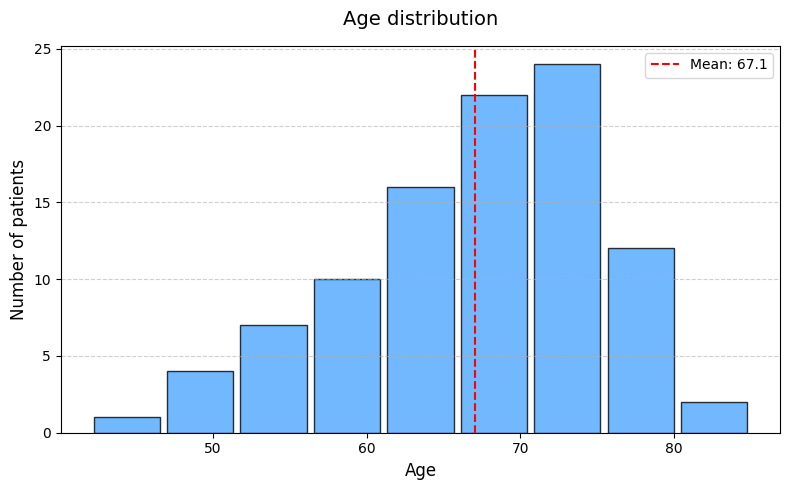

In [8]:
# Age distribution 
if "Age" in df.columns:
    plt.figure(figsize=(8, 5))
    valid_age = df["Age"].dropna()
    bins = max(8, min(25, int(math.sqrt(len(valid_age))))) if len(valid_age) > 0 else 10

    n, bins, patches = plt.hist(
        valid_age,
        bins=bins,
        color="#4da6ff",
        edgecolor="black",
        alpha=0.8,
        rwidth=0.9  
    )

    mean_age = valid_age.mean()
    median_age = valid_age.median()
    plt.axvline(mean_age, color="red", linestyle="dashed", linewidth=1.5, label=f"Mean: {mean_age:.1f}")

    plt.title("Age distribution", fontsize=14, pad=15)
    plt.xlabel("Age", fontsize=12)
    plt.ylabel("Number of patients", fontsize=12)
    plt.grid(axis="y", linestyle="--", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()
    

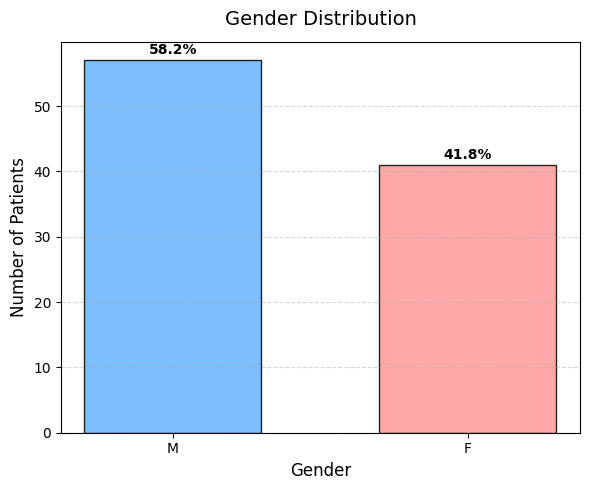

In [9]:
# Gender distribution
if "Gender" in df.columns:
    plt.figure(figsize=(6, 5))
    
    counts = df["Gender"].fillna("Unknown").value_counts()
    total = counts.sum()
    percentages = (counts / total * 100).round(1)
    
    bars = plt.bar(
        counts.index.astype(str),
        counts.values,
        color=["#66b3ff", "#ff9999", "#c2c2f0", "#99ff99"],
        edgecolor="black",
        alpha=0.85,
        width=0.6
    )

    for bar, value, pct in zip(bars, counts.values, percentages):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f"{pct}%",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

    plt.title("Gender Distribution", fontsize=14, pad=12)
    plt.xlabel("Gender", fontsize=12)
    plt.ylabel("Number of Patients", fontsize=12)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()

    plt.show()

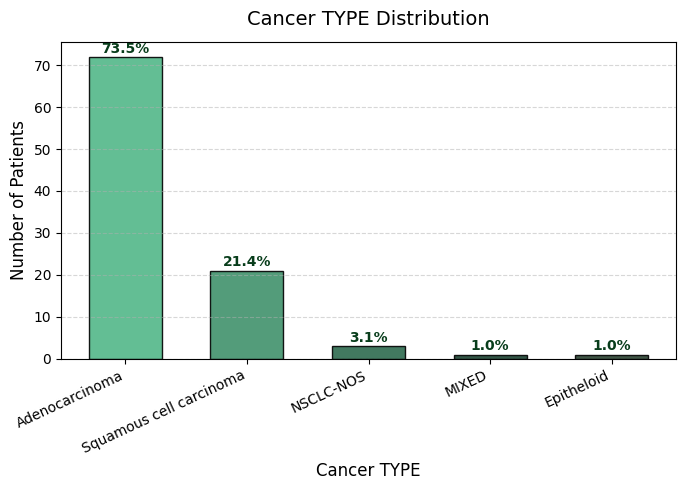

In [10]:
if "TYPE" in df.columns:
    plt.figure(figsize=(7, 5))

    type_counts = df["TYPE"].fillna("Unknown").value_counts()
    total = type_counts.sum()
    percentages = (type_counts / total * 100).round(1)

    colors = ["#52b788", "#40916c", "#2d6a4f", "#1b4332", "#2b4332"]

    bars = plt.bar(
        type_counts.index.astype(str),
        type_counts.values,
        color=colors[:len(type_counts)],
        edgecolor="black",
        alpha=0.9,
        width=0.6
    )

    for bar, value, pct in zip(bars, type_counts.values, percentages):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            f"{pct}%",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            color="#083d1b"
        )

    plt.title("Cancer TYPE Distribution", fontsize=14, pad=12)
    plt.xlabel("Cancer TYPE", fontsize=12)
    plt.ylabel("Number of Patients", fontsize=12)
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()

    plt.show()

C:\Users\Next\AppData\Local\Temp\ipykernel_23324\3065204895.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("Greens", len(values))


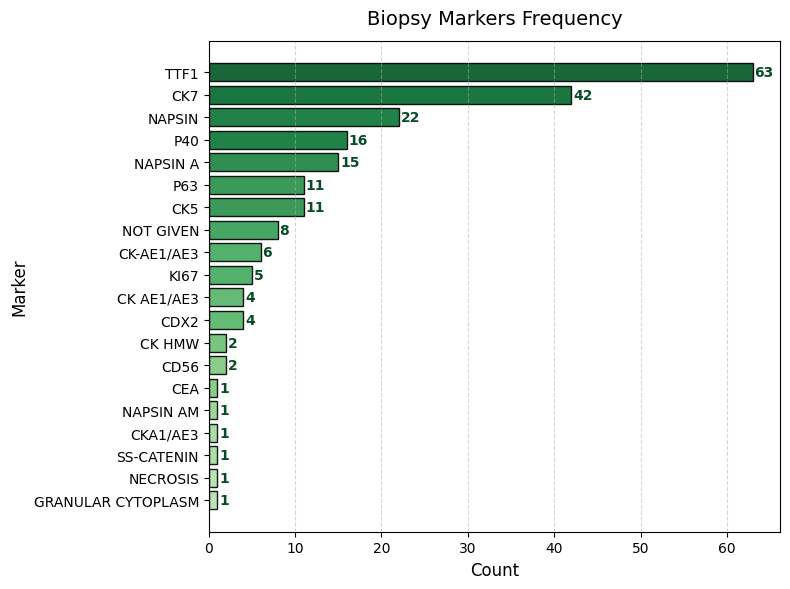

In [11]:
# Biopsy markers frequency 
if "Biopsy positive" in df.columns:
    markers_series = df["Biopsy positive"].dropna()
    all_markers = []
    for entry in markers_series:
        parts = [x.strip().upper() for x in str(entry).split(",") if x.strip()]
        all_markers.extend(parts)

    counter = Counter(all_markers)
    if counter:
        marker_items = sorted(counter.items(), key=lambda kv: kv[1], reverse=True)
        top_n = 20
        labels = [k for k, _ in marker_items[:top_n]]
        values = [v for _, v in marker_items[:top_n]]

        plt.figure(figsize=(8, 6))

        cmap = cm.get_cmap("Greens", len(values))
        colors = [cmap(x) for x in np.linspace(0.9, 0.3, len(values))]

        bars = plt.barh(labels[::-1], values[::-1],
                        color=colors[::-1],
                        edgecolor="black",
                        alpha=0.9)

        for bar, value in zip(bars, values[::-1]):
            plt.text(
                bar.get_width() + 0.2,          
                bar.get_y() + bar.get_height()/2,
                str(value),
                va="center",
                fontsize=10,
                fontweight="bold",
                color="#084c27"
            )

        plt.title("Biopsy Markers Frequency", fontsize=14, pad=12)
        plt.xlabel("Count", fontsize=12)
        plt.ylabel("Marker", fontsize=12)
        plt.grid(axis="x", linestyle="--", alpha=0.5)
        plt.tight_layout()

        plt.show()


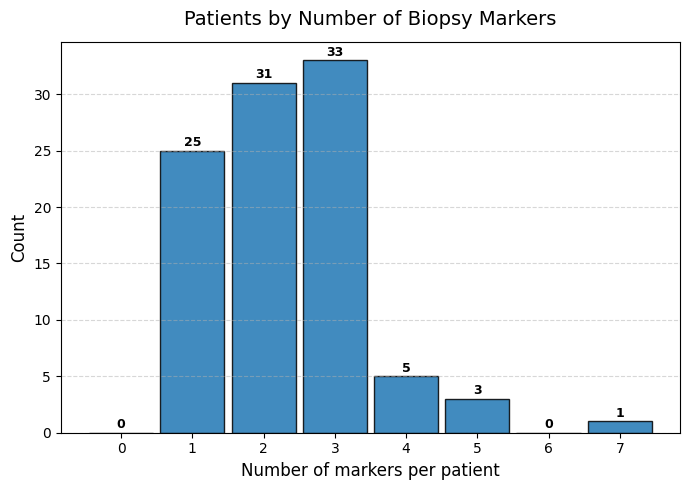

In [12]:
# Patients by number of biopsy markers

def count_markers(s):
    if pd.isna(s):
        return 0
    return sum(1 for x in str(s).split(",") if x.strip())

counts = df["Biopsy positive"].map(count_markers)

plt.figure(figsize=(7, 5))
bins = range(0, counts.max() + 2)

n, bins, patches = plt.hist(
    counts,
    bins=bins,
    rwidth=0.9,
    edgecolor="black",
    alpha=0.85
)

bin_centers = [(bins[i] + bins[i+1]) / 2 for i in range(len(bins) - 1)]
plt.xticks(bin_centers, [str(int(x)) for x in bin_centers])

for x, v in zip(bin_centers, n):
    plt.text(
        x, v + 0.15,
        f"{int(v)}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

plt.title("Patients by Number of Biopsy Markers", fontsize=14, pad=12)
plt.xlabel("Number of markers per patient", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


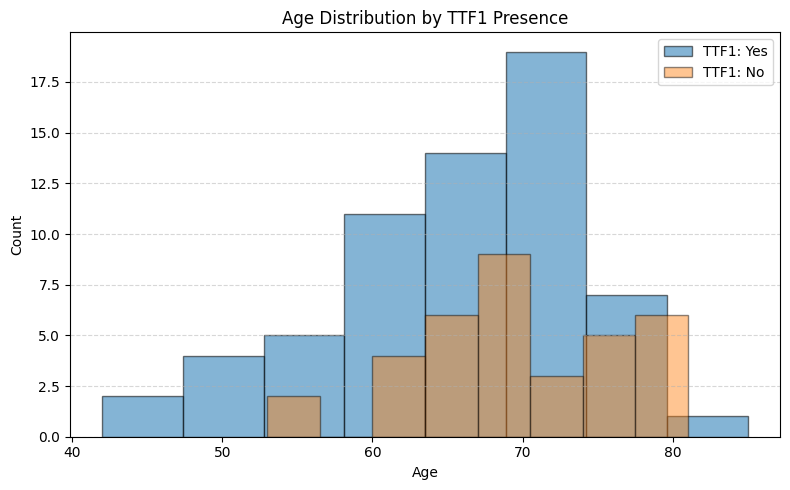

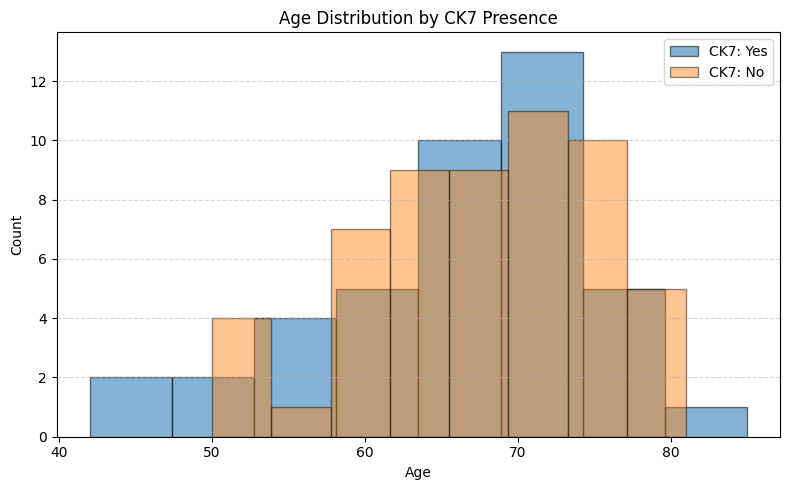

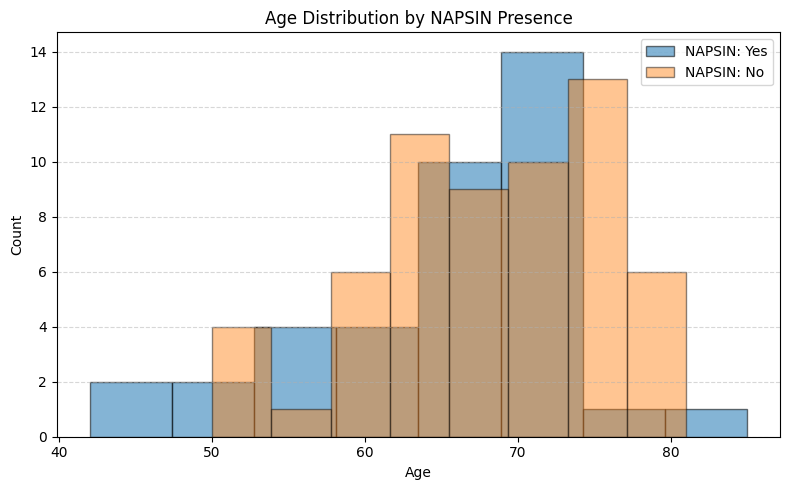

In [13]:
# D) Age distribution split by marker presence —  for TOP-3 markers

import math

def split_markers(s):
    if pd.isna(s): return []
    return [x.strip().upper() for x in str(s).split(",") if x.strip()]

marker_lists = df["Biopsy positive"].dropna().map(split_markers).tolist()
top3 = [m for m, _ in Counter([m for lst in marker_lists for m in lst]).most_common(3)]

for TARGET in top3:
    has = pd.to_numeric(df[df["Biopsy positive"].fillna("").str.upper().str.contains(rf"\b{TARGET}\b", regex=True)]["Age"], errors="coerce").dropna()
    not_has = pd.to_numeric(df[~df["Biopsy positive"].fillna("").str.upper().str.contains(rf"\b{TARGET}\b", regex=True)]["Age"], errors="coerce").dropna()
    if len(has) == 0 and len(not_has) == 0:
        continue

    plt.figure(figsize=(8, 5))
    for series, label, alpha in [(has, f"{TARGET}: Yes", 0.55), (not_has, f"{TARGET}: No", 0.45)]:
        if len(series) == 0: 
            continue
        bins = max(8, min(25, int(math.sqrt(len(series)))))
        plt.hist(series, bins=bins, alpha=alpha, edgecolor="black", label=label)

    plt.title(f"Age Distribution by {TARGET} Presence")
    plt.xlabel("Age")
    plt.ylabel("Count")
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()
